# 01. Data Audit & Temporal Validation Setup

**Project:** Sasol Loyalty Customer Value & Opportunity Prediction

### Objectives:
1. Inspect raw transaction dataset schema, date range, and record counts.
2. Audit basket structures (`TransactionId`, `LineItemSequence`, `LineItemType`).
3. Verify data integrity and preservation of literal `"NA"` category string.
4. Audit customer transaction frequency and eligibility criteria (>= 3 baskets).
5. Validate the Out-Of-Time (OOT) temporal validation split at cutoff `2025-09-01`.

In [2]:
%load_ext autoreload
%autoreload 2

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sasol_customer_value import config
from sasol_customer_value.data import load_transactions, load_test_customers, load_sample_submission
from sasol_customer_value.utils.helpers import set_seed

set_seed(config.RANDOM_SEED)
sns.set_theme(style="whitegrid")
print("Project Root:", config.PROJECT_ROOT)

Project Root: C:\dev\data-science\sasol-customer-value


## 1. Load Raw Transactions and Test Customer Cohort

In [3]:
print("Loading transactions...")
df_train = load_transactions()
df_test = load_test_customers()
df_sample = load_sample_submission()

n_rows = len(df_train)
n_cust = df_train[config.ID_COL].nunique()
n_test = len(df_test)
min_date = df_train[config.DATETIME_COL].min()
max_date = df_train[config.DATETIME_COL].max()

print(f"Train transactions: {n_rows:,} rows across {n_cust:,} unique customers")
print(f"Test cohort: {n_test:,} customers requiring predictions")
print(f"Transaction date range: {min_date} to {max_date}")

Loading transactions...
Train transactions: 467,880 rows across 6,204 unique customers
Test cohort: 5,488 customers requiring predictions
Transaction date range: 2024-03-19 00:07:04.707000 to 2025-11-30 23:39:14.567000


## 2. Inspect Schema & Data Integrity

In [4]:
# Check data types, nulls, and unique values
info_df = pd.DataFrame({
    "Data Type": df_train.dtypes.astype(str),
    "Null Count": df_train.isnull().sum(),
    "Null %": (df_train.isnull().mean() * 100).round(2),
    "Unique Values": df_train.nunique()
})
info_df

,Data Type,Null Count,Null %,Unique Values
DateTimeZA,datetime64[us],0,0.0,365633
TransactionId,str,0,0.0,365638
LineItemSequence,int64,0,0.0,103
LocationId,str,0,0.0,390
ID,str,0,0.0,6204
LineItemType,str,0,0.0,3
TransactionTotalInclAmount,float64,0,0.0,54475
StockItemId,str,0,0.0,6849
ItemName,str,0,0.0,15816
ItemCategoryLevel1,str,0,0.0,8


## 3. Verify String "NA" Category Preservation

Competition rules specify that `"NA"` in `ItemCategoryLevel2` is a valid retail category and must NOT be converted to `NaN`.

In [5]:
level2_counts = df_train["ItemCategoryLevel2"].value_counts(dropna=False)
print("Top 10 ItemCategoryLevel2 values:")
print(level2_counts.head(10))
print("\nIs NaN present in ItemCategoryLevel2?:", df_train["ItemCategoryLevel2"].isna().any())
print("Count of literal 'NA' category:", (df_train["ItemCategoryLevel2"] == "NA").sum())

Top 10 ItemCategoryLevel2 values:
ItemCategoryLevel2
Fuel               342763
Beverages           43820
Food & beverage     20009
Confectionary       14415
Snacking            10359
Tobacco              5575
Breads & rolls       4603
Groceries            4534
Carrier Bags         4260
Lubricants           3747
Name: count, dtype: int64

Is NaN present in ItemCategoryLevel2?: False
Count of literal 'NA' category: 1699


## 4. Customer Basket & Eligibility Analysis

In [6]:
# Baskets per customer across the observation window
baskets_per_cust = df_train.groupby(config.ID_COL)["TransactionId"].nunique()
print("Baskets per customer summary:")
print(baskets_per_cust.describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9, 0.95]))

# Check test customer presence in train dataset
test_ids = set(df_test[config.ID_COL])
train_ids = set(df_train[config.ID_COL])
overlap = len(test_ids.intersection(train_ids))
print(f"Test IDs present in historical train data: {overlap:,} / {len(test_ids):,} ({overlap / len(test_ids):.1%})")

Baskets per customer summary:
count    6204.000000
mean       58.935848
std        89.794250
min         1.000000
10%         2.000000
25%         8.000000
50%        29.000000
75%        75.000000
90%       141.000000
95%       208.850000
max      1302.000000
Name: TransactionId, dtype: float64
Test IDs present in historical train data: 5,488 / 5,488 (100.0%)


## 5. Temporal Volume & Validation Split Setup

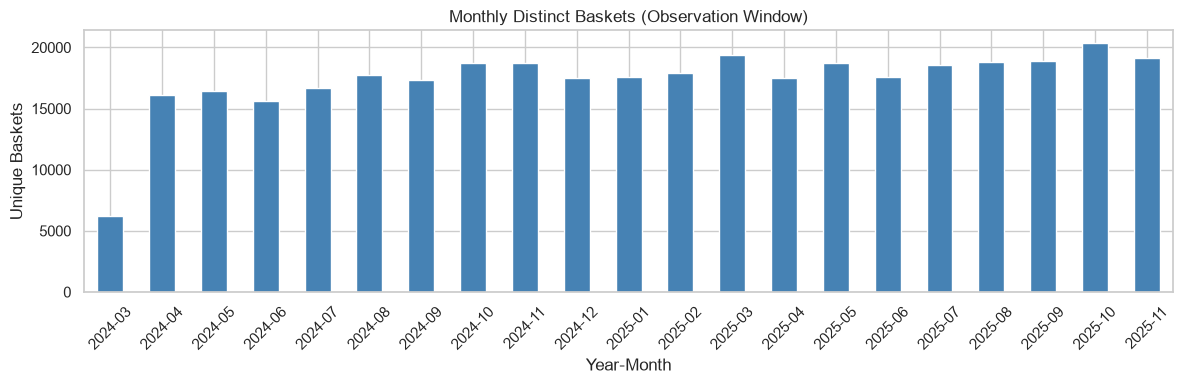

Primary Out-Of-Time validation cutoff: 2025-09-01
Validation feature window: records strictly before 2025-09-01
Validation outcome window: 2025-09-01 to 2025-12-01 (3 full months)


In [7]:
# Monthly transaction volume
df_train["YearMonth"] = df_train[config.DATETIME_COL].dt.to_period("M")
monthly_vol = df_train.groupby("YearMonth")["TransactionId"].nunique()

plt.figure(figsize=(12, 4))
monthly_vol.plot(kind="bar", color="steelblue")
plt.title("Monthly Distinct Baskets (Observation Window)")
plt.xlabel("Year-Month")
plt.ylabel("Unique Baskets")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("Primary Out-Of-Time validation cutoff: 2025-09-01")
print("Validation feature window: records strictly before 2025-09-01")
print("Validation outcome window: 2025-09-01 to 2025-12-01 (3 full months)")